<a href="https://colab.research.google.com/github/100522401/P1_AA_100522396_100522401/blob/main/notebooks/Cuaderno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 1

**Mateo Zariquiey Pérez 100522396**

**Héctor Fuertes Muñoz 100522401**


# 1. Introducción



El objetivo de la práctica es **construir un modelo** de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo. Para construir ese modelo nos basaremos en la información demográfica, financiera e interacciones de los clientes.

Como variable objetivo del problema tenemos 'deposit'. Esta variable indicará si el cliente contrató, o no, el producto ofrecido. Por tanto, se trata de un problema de **clasificación binaria**.
<br><br>
En este cuaderno se incluye:

  - Exploratory Data Analysis (EDA).
  - Definir una estrategia de evaluación.
  - Optimización de hiperparámetros (HPO).
  - Selección del mejor modelo y estudio de su rendimiento.
  - Entrenamiento del modelo final.

# 2. Configuración inicial y carga de datos

En esta sección se importan las librerías básicas usadas, se fija la semilla con el NIA 1005224**01** y se cargan los datos.

En primer lugar, se importan las librerías básicas y fijamos la semilla aleatoria.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 100522401
np.random.seed(SEED)


Se carga el dataset. Se ha escogido el dataset **01** ya que se ha usado como referencia el NIA 1005224**01**

In [ ]:
import os

BASE_DIR = "../data/"
TRAIN_PATH = os.path.join(BASE_DIR, "bank_01.pkl")

print("TRAIN_PATH:", TRAIN_PATH)

TRAIN_PATH: ../data/bank_01.pkl


Se comprueba que el dataset se ha cargado correctamente

In [ ]:
try:
    data = pd.read_pickle(TRAIN_PATH)
    display(data.head())
    print("\nDatos cargados correctamente.")
except Exception as e:
    print(f"ERROR: {e}")

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



Datos cargados correctamente.


# 3. EDA

En esta sección se realiza un análisis exploratorio de los datos (EDA) básico.

En este estudio determinaremos:

- Número de instancias.
- Número de variables ( incluyendo la variable objetivo).
- Identificación de variables numéricas, categóricas u ordinales.
- Estudio de cardinalidad.
- Análisis de la variable 'pdays'.
- Estudio de los valores faltantes, constantes o identificadores.
- Estudio del problema y análisis de desbalanceos de la variable objetivo.


## 3.1 Tamaño del dataset y tipo de problema

En este bloque se calcula el tamaño del dataset (número de instancias y variables). También se verifica que la variable objetivo existe. Se comprueba cuántos valores únicos tienen deposit para confirmar el tipo de problema.

In [ ]:
#Tamaño del dataset y tipo de problema
n_rows, n_cols = data.shape
print(f"Instancias: {n_rows}")
print(f"Variables totales (incluyendo target): {n_cols}")

target = "deposit"
if target not in data.columns:
    raise ValueError(f"No existe la variable objetivo '{target}' en el dataset.")

n_unique_target = data[target].nunique(dropna=False)
print(f"Variable objetivo: {target}")
print(f"Valores únicos en target: {n_unique_target}")

# La variable 'deposit' indica si suscribe o no: problema de clasificación binaria.
if n_unique_target == 2:
    problem_type = "clasificación binaria"
else:
    problem_type = "clasificación (revisar codificación de clases)"

print(f"Tipo de problema: {problem_type}")

Instancias: 11000
Variables totales (incluyendo target): 17
Variable objetivo: deposit
Valores únicos en target: 2
Tipo de problema: clasificación binaria


En este caso tenemos dos clases, y por lo tanto se concluye que es un problema de **clasificación binaria** (se suscribe o no se suscribe). Es importante tener esto en cuenta ya que condiciona la elección de modelos y métricas en el resto de la práctica.

## 3.2 Tipos de variables

En este bloque se identifican los tipos de variables, separándolas en numéricas (donde se incluyen las booleanas) y categóricas. Esta distinción ayudará a definir el preprocesado, ya que las variables numéricas y categóricas requieren transformaciones distintas.

In [ ]:
# Tipos de variables
X = data.drop(columns=[target])

num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Numéricas: {len(num_cols)}")
print(num_cols)
print("\nCategóricas: {0}".format(len(cat_cols)))
print(cat_cols)

Numéricas: 7
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categóricas: 9
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 3.3 Cardinalidad en variables categóricas

Ahora se calculará la cardinalidad (número de valores únicos) de las variables categóricas para detectar posibles casos de alta cardinalidad. Es importante tenerlo en cuenta porque al aumentar la dimensionalidad del conjunto de datos, aumenta el coste computacional y el rendimiento del modelo.

In [ ]:
# Cardinalidad en variables categóricas
if len(cat_cols) == 0:
    print("No hay variables categóricas.")
else:
    cardinality = X[cat_cols].nunique(dropna=False).sort_values(ascending=False)
    display(cardinality.to_frame("n_unique"))

    high_card_cols = cardinality[cardinality > 10].index.tolist()
    if high_card_cols:
      print("\nCategóricas con alta cardinalidad (>10):", high_card_cols)
    else:
      print("\nCategóricas con alta cardinalidad (>10): ninguna")

,n_unique
job,13
month,12
education,5
poutcome,4
marital,3
contact,3
default,2
housing,2
loan,2



Categóricas con alta cardinalidad (>10): ['job', 'month']


En este caso, se observa que hay dos columnas que superan el umbral de alta caridnalidad (> 10 valores únicos).

## 3.4 Valores faltantes

A continuación se analizarán los valores faltantes del dataset, calculando para cada variable cuántos valores nulos aparecen y qué porcentaje representan. Esta información es importante para decidir qué estrategia se utilizará en el preprocesado (imputación)

In [ ]:
# 4) Valores faltantes
missing_count = data.isna().sum().sort_values(ascending=False)
missing_ratio = (missing_count / len(data) * 100).round(2)
missing_df = pd.DataFrame({"n_missing": missing_count, "pct_missing": missing_ratio})
missing_df = missing_df[missing_df["n_missing"] > 0]

if missing_df.empty:
    print("No hay valores faltantes.")
else:
    display(missing_df)


,n_missing,pct_missing
education,316,2.87
job,169,1.54


Se observa que hay dos variables con valores faltantes. Estas variables requerirán una estrategia de imputación en el preprocesado, que constará en el pipeline. Esto evitará problemas durante el entrenamiento de los modelos.

## 3.5 Detección de valores `None` en variables categóricas

Los valores faltantes representados en el dataset no solo pueden ser `NaN`. Es conveniente comprobar si en las variables categóricas aparecen valores `None` o `"None"`. Esto es importante ya que, si no se tratan correctamente, estos valores pasan a ser considerados por el OneHotEncoder generando variables como `job_None` o `education_None`.

El equipo se da cuenta de este error gracias a la gráfica realizada en el punto **7.3 Análisis modelo lineal**, en el que se estudia cómo afectan y qué influencia tienen las distintas variables en el modelo de regresión logística. El resultado mostraba cómo variables como `job_None` o `education_None` tenían mucho peso a la hora de decidir.

In [ ]:
none_cat = data[cat_cols].apply(lambda col: col.map(lambda x: x is None).sum())
none_cat = none_cat[none_cat > 0].sort_values(ascending=False)

if none_cat.empty:
    print("No se han detectado valores None en las variables categóricas.")
else:
    print(none_cat)

education    316
job          169
dtype: int64


Se ha detectado que todos los valores faltantes existentes están representados como `None`. Estos valores deben ser tratados correctamente (teniendo en cuenta que son `None` y no `NaN`) ya que, si no, pueden convertirse en variables artificiales como `job_None` o `education_None`, lo que distorsionaría la interpretación del modelo.

## 3.5 Columnas constantes o tipo ID

Se buscan posibles columnas problemáticas para el modelado: columnas constantes y columnas tipo ID (con valores casi únicos o identificables). Este tipo de variables aporta poca capacidad predictiva y puede introducir ruido o sobreajuste, por lo que es mejor detectarlas antes del preprocesado.

In [ ]:
# 5) Columnas constantes y posibles ID
nunique = X.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()

id_like_by_name = [c for c in X.columns if "id" in c.lower()]
id_like_by_uniqueness = [c for c in X.columns if X[c].nunique(dropna=False) >= 0.98 * len(X)]
id_like_cols = sorted(set(id_like_by_name + id_like_by_uniqueness))

print("Columnas constantes:", constant_cols if constant_cols else "ninguna")
print("Posibles columnas ID:", id_like_cols if id_like_cols else "ninguna")

Columnas constantes: ninguna
Posibles columnas ID: ninguna


No se han detectado **columnos constantes** ni **posibles columnas tipo ID** en el dataset. Por tanto, no es necesario eliminar variables por estos motivos en el preprocesado y modelado.

## 3.6 Desbalanceo del target

Ahora se analizará la distribución de la variable objetivo **deposit**, ya que en problemas de clasificación el desbalanceo relevante realmente es el de las clases que se buscan predecir. Esta información será útil para justificar la elección de la métrica y la comparación entre modelos.

Conteo por clase:
deposit
no     5780
yes    5220
Name: count, dtype: int64

Porcentajes (%):
deposit
no     52.55
yes    47.45
Name: proportion, dtype: float64

Imbalance ratio (mayor/minor): 1.11


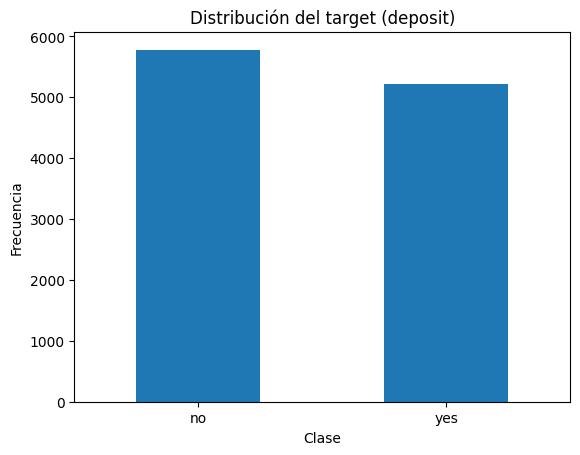

In [ ]:
# Desbalanceo del target

counts = data[target].value_counts(dropna=False)
perc = data[target].value_counts(normalize=True, dropna=False) * 100

# Conteo y porcentaje por clase
print("Conteo por clase:")
print(counts)

print("\nPorcentajes (%):")
print(perc.round(2))

# Ratio de desbalanceo (mayor/minor)
imbalance_ratio = counts.max() / counts.min()
print("\nImbalance ratio (mayor/minor):", round(imbalance_ratio, 2))

# Gráfico
ax = counts.plot(kind="bar")
plt.title("Distribución del target (deposit)")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.xticks(rotation=0)
plt.show()

La variable objetivo presenta una distribución de 52,55% para la clase no y 47,45% para la clase yes. Por tanto, el problema puede considerarse prácticamente equilibrado, con un desbalanceo poco notorio.

## 3.7 Análisis pdays

En este bloque se analiza la variable **pdays**, la cual representa el número de días desde el último contacto en la campaña anterior y tomará el valor **-1** cuando el cliente no ha sido contactado previamente. Entonces, se calculará la proporción de valores `-1`, y se localizarán los valores válidos `(pdays!=-1)` para decidir como tratar la variable en el preprocesado.

In [ ]:
# Analisis de pdays
p = data["pdays"]

n_total = len(p)
n_minus1 = (p == -1).sum()
pct_minus1 = 100 * n_minus1 / n_total

print(f"Total: {n_total}")
print(f"pdays = -1 (sin contacto previo): {n_minus1} ({pct_minus1:.2f}%)")

p_valid = p[p != -1]
print("\nResumen pdays (solo contactos previos reales):")
n_notminus1 = (p != -1).sum()
pct_notminus1 = 100 * n_notminus1 / n_total
print(f"pdays != -1 (solo contactos previos reales): {n_notminus1} ({pct_notminus1:.2f}%)")

display(p_valid.describe())



Total: 11000
pdays = -1 (sin contacto previo): 8203 (74.57%)

Resumen pdays (solo contactos previos reales):
pdays != -1 (solo contactos previos reales): 2797 (25.43%)


count    2797.000000
mean      204.718627
std       122.397953
min         1.000000
25%        98.000000
50%       182.000000
75%       286.000000
max       854.000000
Name: pdays, dtype: float64

Se observa que **pdays == -1** aparece en **8203 de 11000 instancias (74.57%)**, lo que indica que en la mayoría de los casos no existe un contacto previo. Por tanto, el valor -1 no debe interpretarse como un valor numérico, ya que no aporta información relevante al modelado. Para los casos de **pdays != -1**, el número de días tiene una distribución amplia (mediana **182**, rango **1 - 854**), lo que aporta información que puede ser útil para el modelado.

## 3.8 Conclusiones EDA

En resumen, el EDA muestra que se trata de un problema de **clasificación binaria** con un target **prácticamente equilibrado**. Se han identificado tanto variables **numéricas** como **categóricas**, lo que será de suma importancia para el preprocesado. En las variables categóricas, `job` y `month` presentan **alta cardinalidad**, y además se han detectado valores faltantes en `job` y `education`, representados como `None`. No se han observado columnas constantes ni identificadores. Por último, la variable `pdays` requiere de un tratamiento específico, ya que el valor `-1` no representa un número de días real, sino ausencia de contacto previo. Todo esto se tendrá en cuenta en el diseño del pipeline.

# 4. Estrategia de evaluación

## 4.1 Evaluación outer




En este bloque se define la **evaluación outer** de la práctica. Para ello, se separan las variables predictoras (`X`) y la variable objetivo (`y`). A continuación se realiza una partición **holdout**, reservando **2/3 de los datos para entrenamiento y 1/3 para test**.

El conjunto de test quedará reservado hasta el final de la práctica, lo que nos permitirá obtener una estimación sobre el rendimiento del modelo sobre datos no vistos.

Además, en este bloque se realiza una **modificación sobre la variable objetivo** (`deposit`) ya que existen modelos que así lo requieren. La variable pasa de ser una variable `yes/no` a ser una **variable binaria** `1/0`. Más concretamente `no -> 0` y ` yes -> 1` . Esta modificación no cambia el significado del problema, sino únicamente la representación de la variable objetivo.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

#Todas las columnas menos la target
X = data.drop(columns='deposit')
#Solo columna target
y = data['deposit']

# Convertir target a variable binaria
y = y.map({"no": 0, "yes": 1})

# Hacemos particiones
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

print("Distribución de clases en y_train (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución de clases en y_test (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Tamaño de X_train: (7333, 16)
Tamaño de X_test: (3667, 16)
Distribución de clases en y_train (%):
deposit
0    52.54
1    47.46
Name: proportion, dtype: float64

Distribución de clases en y_test (%):
deposit
0    52.55
1    47.45
Name: proportion, dtype: float64


## 4.2 Métrica principal

En esta práctica se utilizará **F1-score** como métrica principal para comparar modelos y seleccionar los hiperparámetros. Se elige esta métrica pese a tener un problema con un desbalanceo leve ya que resume en un único valor el equilibrio entre **precision** y **recall**. Esto permitirá en general **no desperdiciar recursos llamando a cualquiera (Precision) y no perder clientes potenciales (Recall)**

Además del F1-score, se añadirán métricas complementarias:


*   **Accuracy**: al tratarse de un problema relativamente equilibrado, aporta información que puede ser útil sobre el porcentaje de aciertos del modelo.

Esta métrica fue candidata para ser métrica principal. Sin embargo, si frente a datasets desbalanceados se utiliza un modelo ciego que elija la clase mayoritaria, se obtendría como resultado un gran accuracy.

Por lo tanto, de un modelo *Dummy* se obtendrían resultados muy positivos que ignorarían por completo los datos del problema.
*   **ROC AUC**: resulta útil como métrica complemetaria ya que mide la capacidad del modelo para separar las distintas clases.
* **Precision**: para valorar la fiabilidad de las predicciones positivas.
* **Recall**: para medir la capacidad del modelo de detectar casos positivos reales.

De esta manera, el **F1-score** será la referencia principal en la comparación entre alternativas, mientras que el resto de métricas se utilizarán como apoyo a la hora de interpretar resultados.



In [ ]:
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

# Métrica principal
f1_scorer = make_scorer(f1_score, pos_label=1)

# Métricas complementarias
SCORING = {
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0.0),
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0.0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0.0) ,
    "roc_auc": "roc_auc"
}

Para medir modelos cuyo coste computacional es inferior, se medirá con las métricas complementarias para obtener así más puntos de vista y poder tener un criterio más formado. No obstante, la métrica utilizada para comparar los distintos modelos y decidir entre ellos a lo largo de la práctica será siempre el **F1-score**

## 4.3 Evaluación inner

La evaluación interna **inner** se realizará mediante una **validación cruzada estratificada de 3 particiones** sobre el conjunto de entrenamiento `X__train` `Y_train`. Se hará uso de esta estrategia para:
* Comparar modelos
* Seleccionar el mejor scaler
* Ajustar hiperparámetros (HPO)

In [ ]:
# Se define la validación cruzada (3-fold)
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

print('\n')
print(cv_inner)



StratifiedKFold(n_splits=3, random_state=100522401, shuffle=True)


# 5. Pipeline de preprocesado


## 5.1 Preprocesado

En esta sección se define la pipeline de preprocesado que se aplicará a los datos antes de entrenar cada modelo. La pipeline se encargará de realizar las transformaciones adecuadas para cada tipo de variable garantizando que estas se realicen de manera consistente. Más concretamente, el pipeline se encargará de:
* **Variables numéricas**: Se tratarán los valores faltantes, en caso de que existieran, mediante imputación con la mediana. También, en caso de ser necesario, se usará escalado de las variables.

*  **Variables categóricas**: Se tratarán los valores faltantes con la categoría más frecuente o moda. A continuación se codificará mediante **One-Hot Encoding**. Puesto que los valores faltantes están representados como `None`, es necesario normalizarlos para realizar la imputación. Para ello se diseñó la función `clean_none_values`, la cual realiza la siguiente transformación `None -> NaN`. De esta manera los valores faltantes serán tratados correctamente por el `SimpleImputer`.

* **Variable** `pdays`: como se ha estudiado en el EDA, el valor `-1` no representa el número de días real, sino ausencia de contacto previo. Por tanto, para tratar este caso se diseñará una función `transform_pdays`. Esta función separa la información en una **variable binaria (contacted_before)** y transforma `pdays` para que contenga únicamente valores numéricos válidos, reemplazando -1 por NaN. De este modo se evita que -1 distorsione el escalado de la variable.

## 5.2 Pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# # Preprocesado pdays
def transform_pdays(X):
  X = X.copy()
  X["contacted_before"] = (X["pdays"] != -1).astype(int)
  X["pdays"] = X["pdays"].replace(-1, np.nan)
  return X

# Preprocesado de None -> NaN
def clean_none_values(X):
    X = X.copy()
    return X.replace({None: np.nan})

def build_preprocessor(num_cols, cat_cols, numeric_scaler=None):
    """Construye el preprocesado para variables numericas y categoricas."""

    # Pipeline para las variables numéricas: imputar NaN con mediana + scaler
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if numeric_scaler is not None:
        numeric_steps.append(("scaler", numeric_scaler))
    numerical_pipeline = Pipeline(numeric_steps)

    # Pipeline para categóricas: imputar NaN con moda + OneHotEncoder
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # ColumnTransformer: Se aplican las transformaciones según el tipo de variable
    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ])

    return preprocessor


def create_pipeline(model, num_cols, cat_cols, numeric_scaler=None):
    """Une el preprocesado y el modelo final en una sola pipeline."""

    preprocessor = build_preprocessor(
        num_cols,
        cat_cols,
        numeric_scaler=numeric_scaler
    )

    return Pipeline([
        ("transform_pdays", FunctionTransformer(transform_pdays)),
        ("clean_none_values", FunctionTransformer(clean_none_values)),
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])


print("Pipeline base de preprocesado definida correctamente.")


Pipeline base de preprocesado definida correctamente.


## 5.3 Preparación de columnas

Al definir el preprocesado, las variables numéricas y categóricas se identifican a partir del conjunto de entrenamiento.

Además, como la variable `contacted_before` se genera dentro de la pipeline a partir de `pdays`, es necesario añadirla manualmente a la lista de variables numéricas para poder recibir el tratamiento adecuado en el `ColumnTransformer`.

In [ ]:
num_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

if "contacted_before" not in num_cols:
    num_cols = num_cols + ["contacted_before"]

# 6. Métodos básicos: KNN y árboles

## 6.1 Selección del mejor scaler para KNN

En esta sección se comparan los diferentes scalers propuestos para determinar cuál es el más adecuado para **KNN** en este problema. Más concretamente se evaluarán el **StandardScaler**, **MinMaxScaler** y **RobustScaler** usando **KNN con hiperparámetros por defecto**.

La comparación entre las distintas alternativas se realiza siguiendo la estrategia de evaluación definida anteriormente, tomando el **F1-score-medio** como criterio principal y utilizando el resto de métrica como apoyo a la hora de interpretar los resultados.


In [ ]:
import time
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Se definen los scalers a comparar
scalers = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "robust": RobustScaler(),
}

# Lista donde se almacenarán los resultados
scaler_results = []

# 3-fold crossvalidation scalers
for scaler_name, scaler in scalers.items():
  # Se crea la pipeline con KNN y scaler actual
    knn_pipe = create_pipeline(
        KNeighborsClassifier(),
        num_cols=num_cols,
        cat_cols=cat_cols,
        numeric_scaler=scaler
    )

    start = time.perf_counter()

    cv_out = cross_validate(
        knn_pipe,
        X_train,
        y_train,
        cv=cv_inner,
        scoring = SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )
    elapsed = time.perf_counter() - start

    # Se guardan las medias y desviaciones de las métricas
    scaler_results.append({
        "scaler": scaler_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),  # Desviación estándar f1-score
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })

# Se muestran los resultados
scaler_results_df = pd.DataFrame(scaler_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(scaler_results_df)

best_scaler_name = scaler_results_df.loc[0, "scaler"]
best_scaler = scalers[best_scaler_name]
print(f"\nMejor scaler para KNN según F1 medio: {best_scaler_name}")

,scaler,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,standard,0.775874,0.007059,0.793946,0.801980,0.751437,0.861728,0.034198,0.166867,1.801841
1,robust,0.748358,0.015967,0.767628,0.770052,0.727874,0.837775,0.034112,0.162164,1.448599
2,minmax,0.688464,0.009610,0.725215,0.745584,0.639655,0.784271,0.036671,0.167327,1.469886



Mejor scaler para KNN según F1 medio: standard


De esta comparación se puede concluir que **StandardScaler** es el scaler que ofrece el mejor rendimiento para KNN, ya que obtiene los valores más altos en todas las métricas evaluadas.

Se observa también que **RobustScaler** ocupa una posición intermedia, con un rendimiento inferior al de StandardScaler pero superior al de MinMaxScaler. Por último, **MinMaxScaler** es el scaler que presenta los peores resultados.

Consecuentemente y a partir de este punto, el scaler seleccionado será **StandardScaler**, y por tanto, se empleará cuando el modelo necesite ser escalado.


De aquí en adelante se empezarán a evaluar modelos. Para recoger los resultados de estos los modelos para más tarde compararlos, se crea la siguiente función.

In [ ]:
# Recoge los resultados de los modelos y los almacena en una lista.
def add_result(results_list, method, configuration, f1_mean, elapsed):
    results_list.append({
        "Método": method,
        "Configuración": configuration,
        "F1 medio": f1_mean,
        "Tiempo total (s)": elapsed
    })

# Se inicializan las listas
model_results = []
advanced_model_results = []

## 6.2 KNN con hiperparámetros por defecto

En esta sección se evalúa un modelo **KNN** con sus hiperparámetros por defecto, utilizando el método de escalado ya seleccionado(**StandardScaler**). El objetivo es obtener una referencia inicial del rendimiento antes de realizar la HPO.

Además se medirá el tiempo de entrenamiento, ya que el coste computacional tendrá también peso en la comparación.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Inner crossvalidation
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Pipeline
pipeline_knn_default = create_pipeline(
    model=KNeighborsClassifier(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Tiempo
start = time.perf_counter()

scores_knn_default = cross_validate(
    pipeline_knn_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
  )

elapsed = time.perf_counter() - start

print("KNN con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_knn_default['test_f1'].mean():.4f} ± {scores_knn_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_knn_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_knn_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_knn_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_knn_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_knn_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

add_result(model_results, "KNN", "por defecto", scores_knn_default["test_f1"].mean(), elapsed)

KNN con hiperparámetros por defecto:

F1 medio: 0.7759 ± 0.0071

Accuracy medio: 0.7939
Precision media: 0.8020
Recall medio: 0.7514
ROC-AUC medio: 0.8617
Tiempo medio de fit: 0.0339 s
Tiempo total CV: 1.4104 s


## 6.3 HPO de KNN
Una vez ya se ha evaluado el KNN con sus hiperparámetros por defecto, se ajustan sus hiperparámetros mediante un `Grid Search` o búsqueda en rejilla y validación cruzada de 3 particiones. El objetivo es comprobar si es posible mejorar el rendimiento del modelo y analizar si la mejora compensa el posible aumento del coste computacional.

En el grid se tendrán en cuenta los hiperparámetros más importantes para este modelo:
* `n_neighbors`: Representa el número de vecinos que tiene en cuenta el modelo para obtener la predicción.
* `weights`: El coste puede ser uniforme o puede variar dependiendo de la distancia a la que se encuentren las instancias que se tienen en cuenta del objetivo a predecir.
* `p`: Es el exponente de la distancia de `Minkowski`.
    + `p = 1`: **Distancia de Manhattan**
    + `p = 2`: **Distancia Euclídea**
    + `p = 3`: **Minkowski general**
    



In [ ]:
from sklearn.model_selection import GridSearchCV

# Pipeline KNN
pipeline_knn = create_pipeline(
    model=KNeighborsClassifier(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Grid
param_grid_knn = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2, 3]
}

grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

#Tiempo
start = time.perf_counter()

grid_knn.fit(X_train, y_train)

elapsed = time.perf_counter() - start

#Resultados
print("KNN con HPO")
print("Mejores hiperparámetros para KNN:", grid_knn.best_params_)
print(f"Mejor F1 medio: {grid_knn.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

add_result(model_results, "KNN", "HPO", grid_knn.best_score_, elapsed)

KNN con HPO
Mejores hiperparámetros para KNN: {'classifier__n_neighbors': 11, 'classifier__p': 2, 'classifier__weights': 'distance'}
Mejor F1 medio: 0.7863
Tiempo total HPO: 32.4066 segundos


Tras la optimización de hiperparámetros, el mejor modelo KNN se obtiene con **11 neighbors**, distancia de **Minkowski** con `p = 2`, que es equivalente a la **distancia euclídea** y la ponderación por distancia (`weights = "distance"`).

Comparado con el **KNN por defecto**, podemos observar una **ligera mejora** en el rendimiento. Esto indica que el ajuste de hiperparámetros sí aporta una ganancia, pero esta no es muy grande. Sin embargo, esta mejora implica un **coste computacional considerablemente mayor**.

En cuanto a las conclusiones de la mejor configuración, el hecho de que esta use 11 neighbors sugiere que, en este caso, KNN funciona mejor con un número de vecinos mediano. Además, es uso de distancias indica que resulta beneficioso dar más importancia a los vecinos más cercanos.

## 6.4 Análisis del efecto de los hiperparámetros en KNN

En esta sección se analiza cómo afectan los principales hiperparámetros de KNN al rendimiento del modelo. Concretamente se estudia el efecto del número de vecinos (`n_neighbors`), la ponderación (`weights`) y el parámetro `p`de la distancia de Minkowski.

Dado que la mejor configuración obtenida utiliza `weights = "distance"`, `p=2`y `n_neighbors = 11`, en este apartado se irán fijando los parametros de dicha configuración para analizar de forma aislada cómo varía el rendimiento del modelo.

En primer lugar se preparan los resultados obtenidos tras realizar el `GridSearch`.

In [ ]:
results_knn = pd.DataFrame(grid_knn.cv_results_)

results_knn_plot = results_knn[[
    "param_classifier__n_neighbors",
    "param_classifier__weights",
    "param_classifier__p",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].copy()

results_knn_plot = results_knn_plot.sort_values("mean_test_score", ascending=False)
display(results_knn_plot.head(10))

,param_classifier__n_neighbors,param_classifier__weights,param_classifier__p,mean_test_score,std_test_score,mean_fit_time,rank_test_score
27,11,distance,2,0.786274,0.007578,0.038276,1
35,15,distance,3,0.785051,0.011949,0.038909,2
39,21,distance,2,0.784560,0.012722,0.043000,3
23,9,distance,3,0.784087,0.008505,0.041056,4
29,11,distance,3,0.783738,0.011119,0.038487,5
17,7,distance,3,0.783243,0.008021,0.045472,6
22,9,uniform,3,0.783104,0.009863,0.047567,7
34,15,uniform,3,0.783064,0.011636,0.038214,8
15,7,distance,2,0.782664,0.003857,0.046653,9
33,15,distance,2,0.782418,0.011701,0.042525,10


A continuación se muestra el plot que compara `uniform`y `distance`fijando el parámetro `p=2`.

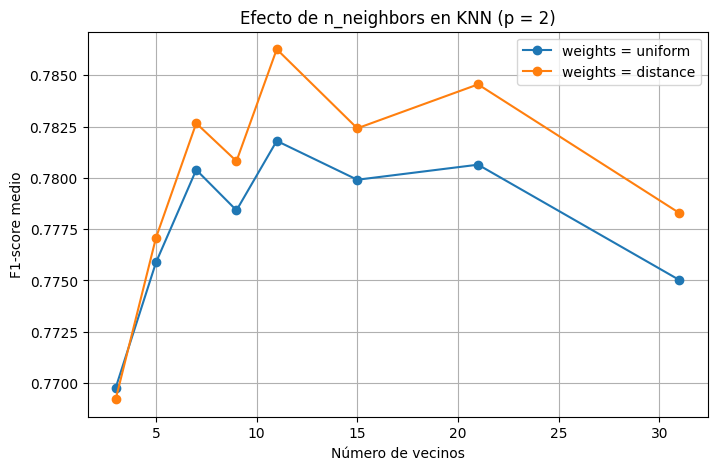

In [ ]:
plt.figure(figsize=(8,5))

for weight_type in results_knn["param_classifier__weights"].unique():
    subset = results_knn[
        (results_knn["param_classifier__weights"] == weight_type) &
        (results_knn["param_classifier__p"] == 2)
    ].sort_values("param_classifier__n_neighbors")

    plt.plot(
        subset["param_classifier__n_neighbors"],
        subset["mean_test_score"],
        marker="o",
        label=f"weights = {weight_type}"
    )

plt.title("Efecto de n_neighbors en KNN (p = 2)")
plt.xlabel("Número de vecinos")
plt.ylabel("F1-score medio")
plt.legend()
plt.grid(True)
plt.show()

Se observa que ambas gráficas tienen una forma similar, pero que la gráfica referente `weights = "distance"` por lo general obtiene un **mayor F1-score medio**.

Ahora se compararán los resultados obtenidos con `p=1`y con `p=2`fijando esta vez `weights = "distance"`.

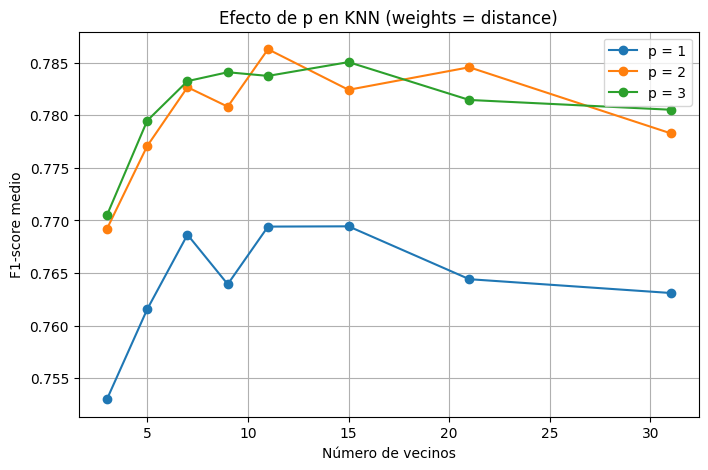

In [ ]:
plt.figure(figsize=(8,5))

for p_value in results_knn["param_classifier__p"].unique():
    subset = results_knn[
        (results_knn["param_classifier__p"] == p_value) &
        (results_knn["param_classifier__weights"] == "distance")
    ].sort_values("param_classifier__n_neighbors")

    plt.plot(
        subset["param_classifier__n_neighbors"],
        subset["mean_test_score"],
        marker="o",
        label=f"p = {p_value}"
    )

plt.title("Efecto de p en KNN (weights = distance)")
plt.xlabel("Número de vecinos")
plt.ylabel("F1-score medio")
plt.legend()
plt.grid(True)
plt.show()

Se observa rápidamente que el rendimiento de `p = 1` es notablemente inferior. Luego el rendimiento entre `p = 2` y `p = 3` varía dependiendo del número de vecinos tenidos en cuenta.

En general, valores muy bajos de `n_neighbors` hacen al modelo más sensible al ruido (favorece el **Overfitting**), mientras que valores más altos hacen que las fronteras de decisión sean muy suaves (puede provocar **Underfitting**). En este problema, el mejor comportamiento se alcanza con un número de vecinos intermedio.

## 6.5 Árboles con hiperparámetros por defecto

A continuación se evalúa un **DecisionTreeClassifier** con sus hiperparámetros por defecto. En este caso, a diferencia de KNN, no es necesario aplicar escalado a las variables numéricas, ya que los árboles no dependen de distancias entre observaciones.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Pipeline
pipeline_tree_default = create_pipeline(
    model=DecisionTreeClassifier(random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=None
)

# Tiempo
start = time.perf_counter()

scores_tree_default = cross_validate(
    pipeline_tree_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start

print("Árbol con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_tree_default['test_f1'].mean():.4f} ± {scores_tree_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_tree_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_tree_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_tree_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_tree_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_tree_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

add_result(model_results, "Árbol", "por defecto", scores_tree_default["test_f1"].mean(), elapsed)

Árbol con hiperparámetros por defecto:

F1 medio: 0.7709 ± 0.0140

Accuracy medio: 0.7841
Precision media: 0.7764
Recall medio: 0.7655
ROC-AUC medio: 0.7832
Tiempo medio de fit: 0.0845 s
Tiempo total CV: 0.1585 s


## 6.6 Árbol poco profundo

Además del árbol con hiperparámetros por defecto, utilizamos un árbol **poco profundo** para obtener una interpretación de cómo podrían tomarse decisiones en este problema. Para ello se entrenará un árbol con profundidad reducida, lo que facilita visualizar las reglas principales de decisión.

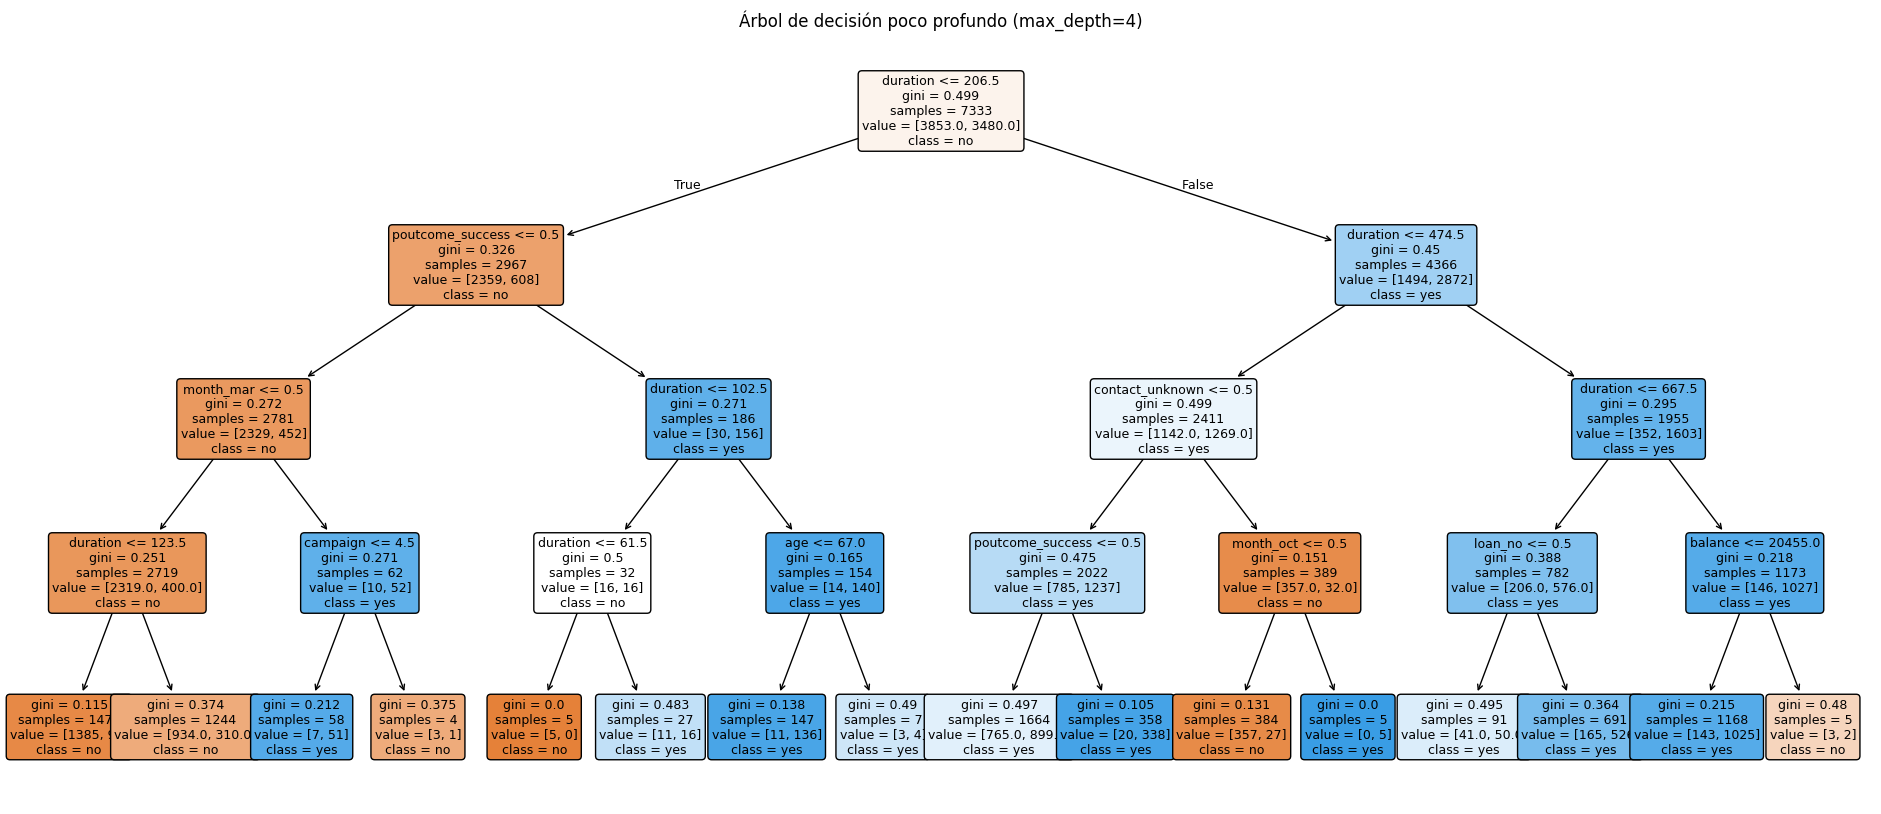

F1 medio: 0.7884
Accuracy media: 0.7757


In [ ]:
from sklearn.tree import plot_tree

# Pipeline del árbol poco profundo
pipeline_tree_shallow = create_pipeline(
    model=DecisionTreeClassifier(max_depth=4, random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=None
)

# Se ajusta el modelo para poder visualizarlo
pipeline_tree_shallow.fit(X_train, y_train)

# Se recuperan los nombres de las variables tras el preprocesado
preprocessor_fitted = pipeline_tree_shallow.named_steps["preprocessor"]
cat_feature_names = preprocessor_fitted.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols)
feature_names = num_cols + list(cat_feature_names)

cv_out_tree_shallow = cross_validate(
    pipeline_tree_shallow,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)


# Representación gráfica del árbol
plt.figure(figsize=(24, 10))
plot_tree(
    pipeline_tree_shallow.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Árbol de decisión poco profundo (max_depth=4)")
plt.show()

print(f"F1 medio: {cv_out_tree_shallow['test_f1'].mean():.4f}")
print(f"Accuracy media: {cv_out_tree_shallow['test_accuracy'].mean():.4f}")


## 6.7 HPO de Árboles
Una vez ya se ha evaluado el árbol con sus hiperparámetros por defecto, en esta subsección se ajustan sus hiperparámetros mediante un `Grid Search` y validación cruzada de 3 particiones. El objetivo es comprobar si es posible mejorar el rendimiento del modelo y analizar si la mejora compensa el posible aumento del coste computacional.

Para realizar el grid se estudiarán los siguientes hiperparámetros:
* `criterion`: Define la fórmula que usa el árbol para decidir que atributo es mejor para dividir los datos en cada paso. Este puede ser:
    + `gini` o **impureza de Gini**.
    + `entropy` o **Entropía**.
* `max_depth`: Define la profundidad máxima del árbol.
* `min_samples_split`: Es el número mínimo de datos que dene tener un nodo para que este pueda seguir dividiéndose.
* `min_samples_leaf`: Es el número mínimo de datos que **obligatoriamente** deben quedar en un nodo hoja.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Pipeline del árbol
pipeline_tree = create_pipeline(
    model=DecisionTreeClassifier(random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=None
)

# Grid
param_grid_tree = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 10, 20, 50],
    "classifier__min_samples_leaf": [1, 5, 10, 20]
}

grid_tree = GridSearchCV(
    estimator=pipeline_tree,
    param_grid=param_grid_tree,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

# Tiempo
start = time.perf_counter()

grid_tree.fit(X_train, y_train)

elapsed = time.perf_counter() - start

# Resultados
print("Trees con HPO")
print("Mejores hiperparámetros para Trees:", grid_tree.best_params_)
print(f"Mejor F1 medio: {grid_tree.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

add_result(model_results, "Árbol", "HPO", grid_tree.best_score_, elapsed)

Trees con HPO
Mejores hiperparámetros para Trees: {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 50}
Mejor F1 medio: 0.8164
Tiempo total HPO: 4.4660 segundos


 Tras la optimización de hiperparámetros, el mejor árbol se obtiene con `criterion = "gini"`, `max_depth = 10`, `min_samples_leaf = 5` y `min_samples_split = 50`. Se aprecia, en comparación con el árbol por defecto una mejora notable en cuanto al **F1-score**. Por tanto, en este caso el ajuste de hiperparámetros sí aporta una ganancia clara de rendimiento. De
hecho, el árbol ajustado **supera** también al **KNN optimizado**, por lo que se convierte en la mejor alternativa dentro de los métodos probados hasta el momento.


## 6.8 Análisis del efecto de los hiperparámetros en árboles

En esta sección se analiza cómo afectan los principales hiperparámetros de los árboles al rendimiento del modelo. Concretamente se estudiará el efecto de `max_depth` y `min_samples_leaf`, fijando el resto de parámetros en la mejor configuración obtenida tras el `Grid Search`.

En primer lugar se preparan los resultados obtenidos tras realizar el `GridSearch`.

In [ ]:
results_tree = pd.DataFrame(grid_tree.cv_results_)

results_tree_plot = results_tree[[
    "param_classifier__criterion",
    "param_classifier__max_depth",
    "param_classifier__min_samples_split",
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].copy()

results_tree_plot = results_tree_plot.sort_values("mean_test_score", ascending=False)
display(results_tree_plot.head(10))


,param_classifier__criterion,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,rank_test_score
55,gini,10,50,5,0.816431,0.012770,0.077112,1
59,gini,10,50,10,0.816140,0.010826,0.117582,2
54,gini,10,20,5,0.815802,0.007503,0.090995,3
56,gini,10,2,10,0.813359,0.007603,0.091402,4
58,gini,10,20,10,0.813359,0.007603,0.114481,4
57,gini,10,10,10,0.813359,0.007603,0.100037,4
50,gini,10,20,1,0.811887,0.011458,0.151711,7
75,gini,None,50,10,0.811245,0.012161,0.080828,8
51,gini,10,50,1,0.811178,0.013311,0.115652,9
53,gini,10,10,5,0.810773,0.005506,0.076535,10


A continuación se muestra el plot que analiza el efecto de `max_depth` fijando el resto de hiperparámetros en la mejor configuración encontrada.

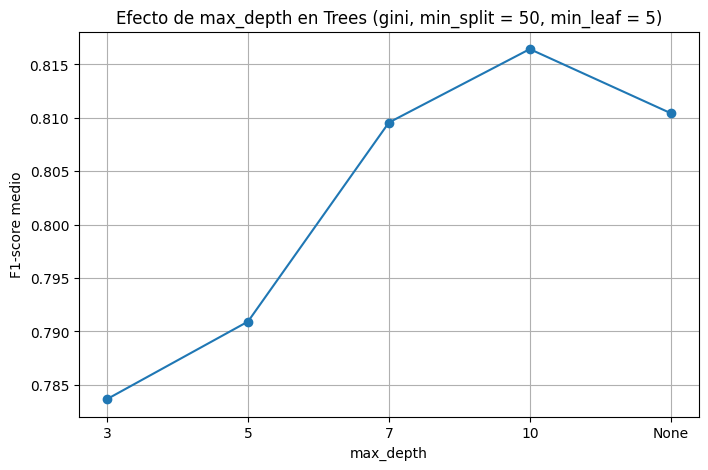

In [ ]:
best_criterion = grid_tree.best_params_["classifier__criterion"]
best_min_samples_split = grid_tree.best_params_["classifier__min_samples_split"]
best_min_samples_leaf = grid_tree.best_params_["classifier__min_samples_leaf"]

subset_depth = results_tree[
    (results_tree["param_classifier__criterion"] == best_criterion) &
    (results_tree["param_classifier__min_samples_split"] == best_min_samples_split) &
    (results_tree["param_classifier__min_samples_leaf"] == best_min_samples_leaf)
].copy()

subset_depth = subset_depth.sort_values(
    by="param_classifier__max_depth",
    key=lambda s: s.apply(lambda x: float("inf") if x is None else x)
)
subset_depth["max_depth_label"] = subset_depth["param_classifier__max_depth"].apply(
    lambda x: "None" if x is None else str(int(x))
)

plt.figure(figsize=(8,5))
plt.plot(
    subset_depth["max_depth_label"],
    subset_depth["mean_test_score"],
    marker="o"
)
plt.title(
    f"Efecto de max_depth en Trees ({best_criterion}, min_split = {best_min_samples_split}, min_leaf = {best_min_samples_leaf})"
)
plt.xlabel("max_depth")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()


  En este gráfico se observa que el rendimiento del árbol mejora de forma progresiva a medida que aumenta max_depth, pasando de peores resultados con profundidades bajas a su mejor resultado en **max_depth = 10**. Sin embargo, cuando se elimina la restricción de profundidad (None), el rendimiento desciende ligeramente. Esto nos indica que el árbol necesita cierta complejidad para capturar bien la estructura del problema, pero que dejarlo crecer sin límite introduce sobreajuste. Por tanto, una profundidad intermedia-alta parece ofrecer el mejor equilibrio entre capacidad predictiva y generalización.

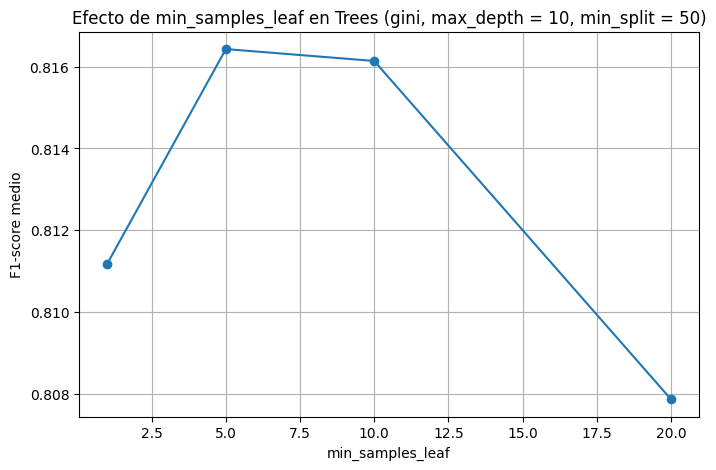

In [ ]:
best_max_depth = grid_tree.best_params_["classifier__max_depth"]

subset_leaf = results_tree[
    (results_tree["param_classifier__criterion"] == best_criterion) &
    (results_tree["param_classifier__max_depth"] == best_max_depth) &
    (results_tree["param_classifier__min_samples_split"] == best_min_samples_split)
].sort_values("param_classifier__min_samples_leaf")

depth_label = "None" if best_max_depth is None else str(int(best_max_depth))

plt.figure(figsize=(8,5))
plt.plot(
    subset_leaf["param_classifier__min_samples_leaf"].astype(int),
    subset_leaf["mean_test_score"],
    marker="o"
)
plt.title(
    f"Efecto de min_samples_leaf en Trees ({best_criterion}, max_depth = {depth_label}, min_split = {best_min_samples_split})"
)
plt.xlabel("min_samples_leaf")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()


 El análisis de `min_samples_leaf` muestra que el mejor rendimiento se obtiene con
  `min_samples_leaf = 5`. Con hojas demasiado pequeñas, el resultado es algo peor, lo que sugiere un mayor riesgo de sobreajuste. Por otro lado, al aumentar demasiado este parámetro, el rendimiento vuelve a descender, indicando que el modelo se vuelve demasiado restrictivo. Por tanto, los resultados apuntan a que una regularización moderada
  mediante hojas pequeñas mejora la capacidad de generalización del árbol.

## 6.9 DummyClassifier


En esta sección se evalúan dos clasificadores **Dummy** para medir el rendimiento de clasificadores **triviales**. Un **DummyClassifier** no aprende patrones reales de los atributos, simplemente predice según una regla muy básica, por ejemplo escoger siempre la clase mayoritaria o generar predicciones aleatorias respetando la distribución de clases.

Esto sirve como base. Si **KNN** o los **árboles** no mejoran claramente a un **dummy**, entonces el modelo no estaría aprendiendo información útil del problema.

In [ ]:
from sklearn.dummy import DummyClassifier

# Se definen los clasificadores dummy a comparar
dummy_models = {
    "most_frequent": DummyClassifier(strategy="most_frequent"),
    "stratified": DummyClassifier(strategy="stratified", random_state=SEED),
}

# Lista donde se guardan los resultados
dummy_results = []

# Evaluación de cada dummy con validación cruzada
for dummy_name, dummy_model in dummy_models.items():
    start = time.perf_counter()

    cv_out = cross_validate(
        dummy_model,
        X_train,
        y_train,
        cv=cv_inner,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start

    # Se guardan las medias de las métricas y los tiempos
    dummy_results.append({
        "modelo": dummy_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })



# Se muestran los resultados ordenados por F1 medio
dummy_results_df = pd.DataFrame(dummy_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(dummy_results_df)

best_dummy_row = dummy_results_df.iloc[0]

add_result(model_results, "Dummy",
    best_dummy_row["modelo"],
    best_dummy_row["f1_mean"],
    best_dummy_row["total_cv_time"]
)

,modelo,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,stratified,0.476707,0.00418,0.500613,0.474132,0.47931,0.499582,0.001286,0.014735,0.034344
1,most_frequent,0.000000,0.00000,0.525433,0.000000,0.00000,0.500000,0.001196,0.012232,0.033331


## 6.10 Conclusiones


Una vez ya se han entrenado y evaluado los **modelos básicos**, se han resumido los resultados obtenidos. En la siguiente tabla se comparan los valores obtenidos en **F1-score** como el **tiempo total** del proceso asociado. Por lo tanto, en esta tabla se podrá visualizar de forma directa las diferencias de rendimiento y coste computacional entre los modelos **KNN** y **árboles de decisión**, tanto en sus versiones por defecto como en sus mejores configuraciones (halladas tras hacer el HPO). También se compararán frente a un clasificador **Dummy** (`DummyClassifier`).

In [ ]:
summary_models = pd.DataFrame(model_results)

summary_models["F1 medio"] = summary_models["F1 medio"].round(4)
summary_models["Tiempo total (s)"] = summary_models["Tiempo total (s)"].round(4)

summary_models = summary_models.sort_values("F1 medio", ascending=False).reset_index(drop=True)

display(summary_models)

,Método,Configuración,F1 medio,Tiempo total (s)
0,Árbol,HPO,0.8164,4.4660
1,KNN,HPO,0.7863,32.4066
2,KNN,por defecto,0.7759,1.4104
3,Árbol,por defecto,0.7709,0.1585
4,Dummy,stratified,0.4767,0.0343


A partir de la tabla, se observa que la mejor alternativa dentro de este estudio es el **árbol de decisión con HPO**, que alcanza el mayor **F1-score medio**. En segundo lugar esta el **KNN con HPO**. Seguido quedan las configuraciones por defecto de ambos métodos, que presentan unos resultados muy similares.

En cuanto al HPO, tanto en **KNN** como en **árboles** se aprecia una mejora respecto a la configuración por defecto. No obstante, esta mejora es más notoria en el caso de los **árboles**.

También conviene señalar que, en las configuraciones con **HPO**, el tiempo mostrado corresponde al **proceso completo de HPO** mediante `GridSearchCV`. Es por esto que es considerablemente mayor que el tiempo necesario para ajustar posteriormente un modelo final.

Para concluir, todos los modelos evaluados superan al **DummyClassifier**, lo que confirma que los métodos estan realmente reteniendo información de los datos. De esta manera, dentor de este bloque, la alternativa más competitiva es el **arbol de decisión con HPO**, ya que combina el mejor rendimiento con un coste computacional razonable.

# 7. Modelos avanzados: lineales y SVM

En esta sección se estudian dos tipos de métodos avanzados de clasificación: los **modelos lineales** y las **máquinas de vectores de soporte (SVM)**. Ambos métodos se evaluarán en primer lugar con sus hiperparámetros por defecto y, luego, se realizará su HPO.

El objetivo será comprobar si estos métodos son capaces de mejorar los resultados obtenidos en el bloque anterior con **KNN** y **árboles**, asi como analizar su coste computacional y capacidades.

## 7.1 Regresión logística con hipérparámetros por defecto

A continuación se evaluará un **regresión logística** con sus hiperparámetros por defecto. Este es un modelo lineal para clasificación binaria cuya salida se transforma mediante una función sigmoide, lo que permite interpretar la predicción como la probabilidad de que pertencezca a al clase positiva.

El objetivo de esta sección es obtener una referencia inicial del rendimiento del modelo antes de realizar la HPO. Tambíen se medirá el tiempo total del proceso para poder comparar posteriormente su coste computacional.

In [ ]:
# Se inicializa nueva tabla comparativa para los modelos avanzados
advanced_model_results = []

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Inner crossvalidation
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Pipeline
pipeline_logreg_default = create_pipeline(
    model=LogisticRegression(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Tiempo
start = time.perf_counter()

scores_logreg_default = cross_validate(
    pipeline_logreg_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
  )

elapsed = time.perf_counter() - start

print("Modelo lineal (Regresión logística) default:\n")
print(f"F1 medio: {scores_logreg_default['test_f1'].mean():.4f} ± {scores_logreg_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_logreg_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_logreg_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_logreg_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_logreg_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_logreg_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

add_result(advanced_model_results, "Regresión logística", "por defecto", scores_logreg_default["test_f1"].mean(), elapsed)

Modelo lineal (Regresión logística) default:

F1 medio: 0.8037 ± 0.0082

Accuracy medio: 0.8189
Precision media: 0.8274
Recall medio: 0.7813
ROC-AUC medio: 0.9012
Tiempo medio de fit: 0.0508 s
Tiempo total CV: 0.1088 s


La regresión logística por defecto ofrece una primera referencia ya muy competitiva respecto a los modelos básicos.

También, al tratarse de un método relativamente simple y con bajo coste computacional, puede llegar a ser una alternativa frente a modelo más complejos.

## 7.2 Modelo lineal con HPO

Tras evaluar el model lineal con sus hiperparámetros por defecto, se pocede a realizar su **HPO** con `GridSearchCV`. El objetivo es comprobar si el rendimiento del modelo mejora y en ese caso comprobar si la mejora compensa el coste computacional adicional.

En caso de la regresión logísitca, los hiperparámetros mas relevantes son:
* `C`: Controla la intensidad de la regularización.
* `l1_ratio` o **penalty** : determina el tipo de regularización utilizada. Esta varía según el valor que se le asigne.
    + `l1_ratio = 1` es equivalente a un `penalty = "l1"`
    + `l1_ratio = 0` es equivalente a un `penalty = "l2"`
    + `0 < l1_ratio < 1` es equivalente a un `penalty = "elasticnet"`

* `solver`: Algoritmo empleado para ajustlar los parámetros del modelo.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Pipeline KNN
pipeline_logreg_hpo = create_pipeline(
    model=LogisticRegression(max_iter=10000, random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Grid
param_grid_logreg = [
    {
        # penalty='l2'
        "classifier__l1_ratio": [0.0],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"]
    },
    {
        # penalty='l1'
        "classifier__l1_ratio": [1.0],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["saga"]
    },
    {
        # penalty='elasticnet'
        "classifier__l1_ratio": [0.2, 0.5, 0.8],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["saga"]
    }
]

grid_logreg = GridSearchCV(
    estimator=pipeline_logreg_hpo,
    param_grid=param_grid_logreg,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

#Tiempo
start = time.perf_counter()

grid_logreg.fit(X_train, y_train)

elapsed = time.perf_counter() - start

# Resultados
print("Regresión logística con HPO")
print("Mejores hiperparámetros:", grid_logreg.best_params_)
print(f"Mejor F1 medio: {grid_logreg.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

add_result(advanced_model_results, "Regresión logística", "HPO", grid_logreg.best_score_, elapsed)

Regresión logística con HPO
Mejores hiperparámetros: {'classifier__C': 10, 'classifier__l1_ratio': 0.0, 'classifier__solver': 'lbfgs'}
Mejor F1 medio: 0.8039
Tiempo total HPO: 10.9040 segundos


Antes de sacar conclusiones, se estudiarán los casos de prueba. En primer lugar, para los valores de `C` se ha escogido una escala logarítmica para poder probar desde una regularización fuerte hasta una débil.

En cuanto a los solvers, se han utilizado únicamente combinaciones compatibles.
* `lbfgs` para `l2`.
* `saga` para `l1` y `elasticnet` ya que permite trabajar con esas regularizaciones y, es necesario para `elasticnet`.

En cuanto a las conclusiones, se ha obtenido que la configuración óptima es **L2**, con `C = 10 ` y `solver = "lbfgs"`. De este resultado se puede decir que, para este problema una regularización estándar y medianamente suave es suficiente para obtener el mejor rendimiento dentro de los casos estudiados.

En comparación con la versión por defecto, el HPO produce una **Mejora ligera** del rendimiento. Sin embargo, aunque con el HPO se afine el modelo, la ganancia en cuanto a rendimiento es leve respecto al coste computacional que requiere.

## 7.3 Análisis modelo lineal

A continuación se analizará mediante la regresión logística de que manera influyen las variables en la predicción y en que medida.

Para ello se hará uso de la **mejor versión de la regresión logística** , es decir, la regresión logística tras HPO. A partir de sus coeficientes se podrá identificar que variables favorecen a la clase positiva (`yes`) y cuales favorecen a la clase negativa (`no`).

En primer lugar, se contruirá una tabla con las variables que tienen los coeficientes absolutos más grandes. En esta tabla se identificará que atributos son los más relevantes para el modelo.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mejor pipeline de regresión logística tras HPO
best_logreg = grid_logreg.best_estimator_

# Recuperar nombres de variables tras el preprocesado
preprocessor_fitted = best_logreg.named_steps["preprocessor"]
cat_feature_names = preprocessor_fitted.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols)
feature_names = num_cols + list(cat_feature_names)

# Coeficientes del clasificador
coefs = best_logreg.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "variable": feature_names,
    "coeficiente": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

display(coef_df.head(20))

,variable,coeficiente,abs_coef
43,month_mar,1.966190,1.966190
3,duration,1.883320,1.883320
50,poutcome_success,1.615098,1.615098
40,month_jan,-1.265782,1.265782
46,month_oct,1.079074,1.079074
45,month_nov,-1.016409,1.016409
41,month_jul,-0.996715,0.996715
35,contact_unknown,-0.967065,0.967065
47,month_sep,0.859151,0.859151
38,month_dec,0.857698,0.857698


Para interpretar correctamente esta tabla es importante tener en cuenta que un coeficiente **positivo** favorece al clase `yes`, mientras que un coeficiente **negativo** favorece la clase `no`. Además, cuanto mayor es el valor absoluto del coeficiente, mayor es el peso de esa variable a la hora de influir en las predicciones del modelo.

También, para una correcta interpretación se debe tener en cuenta que las variables seguidas de un `_atributo`, como por ejemplo, `month_oct` son variables categóricas que han sido transformadas mediante **One-Hot Encoding**.

A partir de los resultados, se observa que variables como , `month_mar`, `duration`y `poutcome_success` son importantes para la predicción ya que empujan el resultado hacia la clase positiva. Al ser `duration`una variable numérica, quiere decir que es directamente proporcional con la probabilidad de que el modelo se decida por la clase `yes`. Por otro lado variables como `month_nov`, `month_jan`, `month_jul` o `contact_unknown` tienen a decidir el resultado hacia la clase negativa o `no`.

Ahora se mostrará un gráfico para visualizar las conclusiones anteriores.

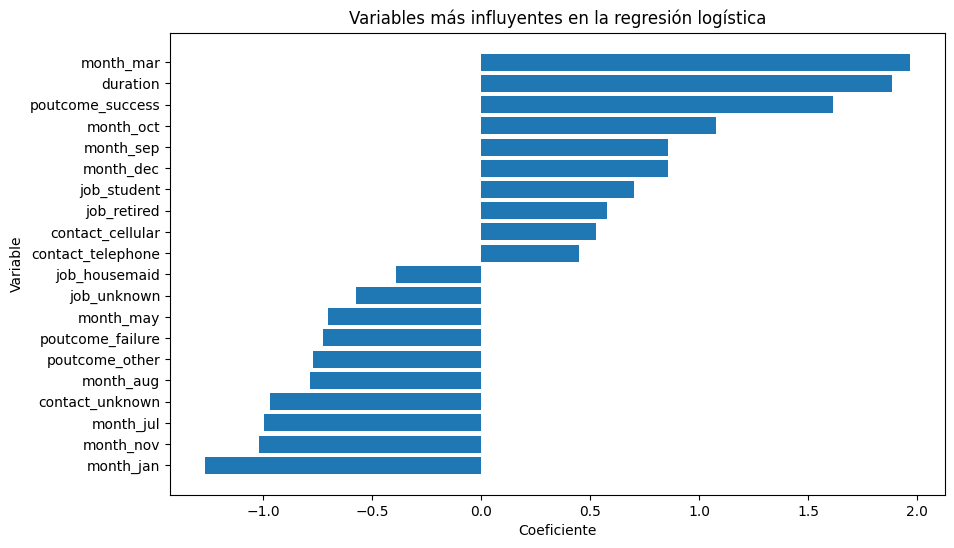

In [ ]:
top_n = 20
top_features = coef_df.head(top_n).sort_values("coeficiente")

plt.figure(figsize=(10, 6))
plt.barh(top_features["variable"], top_features["coeficiente"])
plt.title("Variables más influyentes en la regresión logística")
plt.xlabel("Coeficiente")
plt.ylabel("Variable")
plt.show()

## 7.4 SVM con hiperparámetros por defecto


En esta sección se evaluará una **máquina de vectores de soporte (SVM)** con sus hiperparámetros por defecto. Este método se resume en buscar una frontera de decisión que separe de la mejor forma (con el mayor margen posible) las clases.

El objetivo es obterner una referencia incial del comportamiento de este modelo antes de proceder con el HPO.

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Inner crossvalidation
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Pipeline
pipeline_svm_default = create_pipeline(
    model=SVC(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Tiempo
start = time.perf_counter()

scores_svm_default = cross_validate(
    pipeline_svm_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
  )

elapsed = time.perf_counter() - start

print("SVM con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_svm_default['test_f1'].mean():.4f} ± {scores_svm_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_svm_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_svm_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_svm_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_svm_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_svm_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

add_result(advanced_model_results, "SVM", "por defecto", scores_svm_default["test_f1"].mean(), elapsed)

SVM con hiperparámetros por defecto:

F1 medio: 0.8409 ± 0.0085

Accuracy medio: 0.8441
Precision media: 0.8155
Recall medio: 0.8678
ROC-AUC medio: 0.9124
Tiempo medio de fit: 0.7390 s
Tiempo total CV: 1.3826 s


Este modelo ya con hiperparámetros por defecto ofrece un rendimiento muy competitivo dentro de los modelos avanzados.

Además, aunque tiene un coste computacional mayor la regresión logística, sigue siendo un coste asumible respecto a su rendimiento.

## 7.5 HPO de SVM

Una vez evaluada la SVM con sus hiperparámetros por defecto, se procederá a ajustar sus principales hiperparámetros mediante un `GridSearchCV`. El objetivo será comprobar si el rendimiento del modelo puede mejorar y analizar si esa mejora compensa el aumento del coste computacional.

Hiperparámetros a optimizar:
* `C`: Controla el equilibrio entre maximizar el margen y la penalización de errores.
* `kernel`: es la función que indica la "similitud" entre instancias. Es decir, determina que forma tendrá la frontera de decisión.

* `gamma`: En los kernels no lineales, controla la influencia de cada instancia.

In [ ]:
from sklearn.svm import SVC

# Pipeline SVM
pipeline_svc = create_pipeline(
    model=SVC(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Grid
param_grid_svc = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__gamma": [0.01, 0.1, 1]
    }
]

grid_svc = GridSearchCV(
    estimator=pipeline_svc,
    param_grid=param_grid_svc,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

#Tiempo
start = time.perf_counter()

grid_svc.fit(X_train, y_train)

elapsed = time.perf_counter() - start

# Resultados
print("SVM con HPO")
print("Mejores hiperparámetros para SVM:", grid_svc.best_params_)
print(f"Mejor F1 medio: {grid_svc.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

add_result(advanced_model_results, "SVM", "HPO", grid_svc.best_score_, elapsed)

SVM con HPO
Mejores hiperparámetros para SVM: {'classifier__C': 1, 'classifier__gamma': 0.1, 'classifier__kernel': 'rbf'}
Mejor F1 medio: 0.8400
Tiempo total HPO: 42.8826 segundos


En concreto se han comparado dos tipos de **kernel**:
* `lineal`, para  comprobar si una frontera de decisión lineal es suficiente.
* **RBF** o `gaussiano`, para estudiar fronteras no lineales más flexibles.

En ambos casos se ajusta `C`. Sin embargo, en el caso del kernel **gaussiano**, también se ajusta `gamma`.

Tras el HPO, la mejor combinación utiliza un **kernel gaussiano** con `C=100` y `gamma = 0.01`. Esto indica que, para este problema, una frontera de decisión **no lineal** es más adecuada.

En comparación con la versión por defecto, el HPO produce una **mejora muy leve** del rendimiento. Por tanto, aunque el HPO permite afinar el modelo, la ganancia obtenida es muy leve respecto al incremento del aumento del coste computacional tras realizar el proceso completo de HPO.

## 7.6 Análisis del efecto de los hiperparámetros en SVM

Una vez ya se ha realizado el HPO se procede a analizar cómo afectan los hiperparámetros estudiados de **SVM** al rendimiento del modelo. Más concretamente se estudiará el efecto del tipo de `kernel`, de `C`, y en el caso del kernel **gaussiano**, de `gamma`.

In [ ]:
results_svm = pd.DataFrame(grid_svc.cv_results_)

results_svm_plot = results_svm[[
    "param_classifier__kernel",
    "param_classifier__C",
    "param_classifier__gamma",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].copy()

results_svm_plot = results_svm_plot.sort_values("mean_test_score", ascending=False)
display(results_svm_plot.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score,mean_fit_time,rank_test_score
12,rbf,1.0,0.10,0.840033,0.007665,3.970995,1
17,rbf,100.0,0.01,0.837890,0.007960,5.186724,2
14,rbf,10.0,0.01,0.836079,0.007205,4.025854,3
15,rbf,10.0,0.10,0.822852,0.006628,4.231764,4
11,rbf,1.0,0.01,0.820132,0.006321,4.127863,5
9,rbf,0.1,0.10,0.816960,0.013192,4.778742,6
2,linear,1.0,NaN,0.809681,0.008898,5.532212,7
3,linear,10.0,NaN,0.808758,0.008613,12.095048,8
4,linear,100.0,NaN,0.808693,0.009107,40.435011,9
1,linear,0.1,NaN,0.808583,0.009332,4.402885,10


En primer lugar se estudiará como mejora o no una SVM lineal dependiendo del valor de `C`.

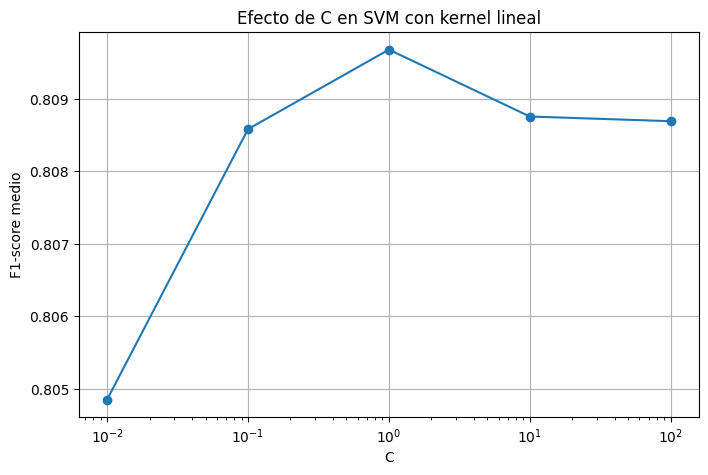

In [ ]:
plt.figure(figsize=(8, 5))

subset_linear = results_svm[
    results_svm["param_classifier__kernel"] == "linear"
].sort_values("param_classifier__C")

plt.plot(
    subset_linear["param_classifier__C"].astype(float),
    subset_linear["mean_test_score"],
    marker="o"
)

plt.xscale("log")
plt.title("Efecto de C en SVM con kernel lineal")
plt.xlabel("C")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()

Se puede observar como el **F1-score** aumenta entre `10e-2` y `10e-1`, y luego permanece medianamente estable.

A continuación se estudiará el efecto de `gamma` con un kernel **gaussiano**. En este caso se fija `C = 100`.

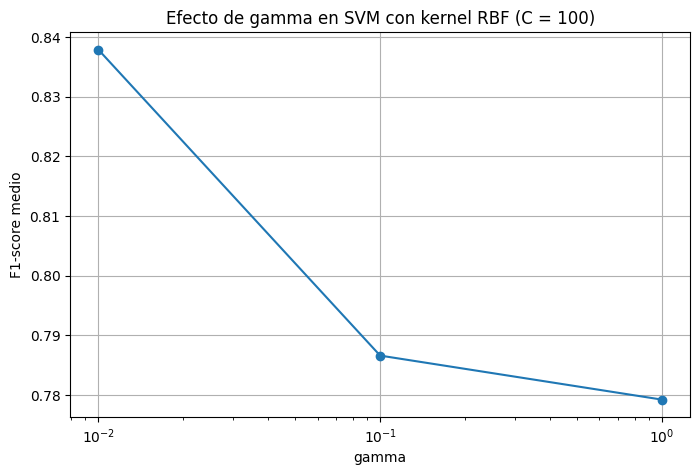

In [ ]:
plt.figure(figsize=(8, 5))

subset_rbf = results_svm[
    (results_svm["param_classifier__kernel"] == "rbf") &
    (results_svm["param_classifier__C"] == 100)
].sort_values("param_classifier__gamma")

plt.plot(
    subset_rbf["param_classifier__gamma"].astype(float),
    subset_rbf["mean_test_score"],
    marker="o"
)

plt.xscale("log")
plt.title("Efecto de gamma en SVM con kernel RBF (C = 100)")
plt.xlabel("gamma")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()

De este gráfico se puede concluir que aumentar el valor de `gamma` conlleva una disminución de F1-score.

Por último se comparará el rendimiento entre el kernel lineal y el kernel RBF.

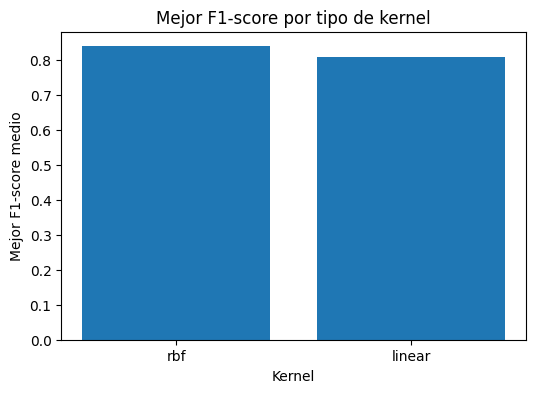

In [ ]:
best_by_kernel = (
    results_svm.groupby("param_classifier__kernel", as_index=False)["mean_test_score"]
    .max()
    .sort_values("mean_test_score", ascending=False)
)

plt.figure(figsize=(6, 4))
plt.bar(best_by_kernel["param_classifier__kernel"], best_by_kernel["mean_test_score"])
plt.title("Mejor F1-score por tipo de kernel")
plt.xlabel("Kernel")
plt.ylabel("Mejor F1-score medio")
plt.show()

Se concluye que el kernel **gaussiano** ofrece un rendimiento superior al kernel **lineal**.

# 8. Resultados y modelo final

En esta sección se selecciona la mejor alternativa usando únicamente la evaluación **inner**. Después, se evalúa esa alternativa una sola vez sobre el conjunto de **test** (evaluación **outer**), y por último se entrena el modelo final con todos los datos disponibles.

In [ ]:
# Se unen tablas métodos básicos y avanzados
all_model_results = pd.concat(
    [pd.DataFrame(model_results), pd.DataFrame(advanced_model_results)],
    ignore_index=True
)

# La selección se hace con los valores completos, dejando el redondeo solo para mostrar la tabla
all_model_results = all_model_results.sort_values(
    by=["F1 medio", "Tiempo total (s)"],
    ascending=[False, True]
).reset_index(drop=True)

# Tabla redondeada para visualización
all_model_results_display = all_model_results.copy()
all_model_results_display["F1 medio"] = all_model_results_display["F1 medio"].round(4)
all_model_results_display["Tiempo total (s)"] = all_model_results_display["Tiempo total (s)"].round(4)

display(all_model_results_display)

# Se selecciona la mejor alternativa inner
best_row = all_model_results.iloc[0].copy()
best_estimator_inner = pipeline_svm_default

print("Selección del mejor modelo usando solo evaluación inner:")
print(f"Método: {best_row['Método']}")
print(f"Configuración: {best_row['Configuración']}")
print(f"F1 medio inner: {best_row['F1 medio']:.4f}")

,Método,Configuración,F1 medio,Tiempo total (s)
0,SVM,por defecto,0.8409,1.3826
1,SVM,HPO,0.8400,42.8826
2,Árbol,HPO,0.8164,4.4660
3,Regresión logística,HPO,0.8039,10.9040
4,Regresión logística,por defecto,0.8037,0.1088
5,KNN,HPO,0.7863,32.4066
6,KNN,por defecto,0.7759,1.4104
7,Árbol,por defecto,0.7709,0.1585
8,Dummy,stratified,0.4767,0.0343


Selección del mejor modelo usando solo evaluación inner:
Método: SVM
Configuración: por defecto
F1 medio inner: 0.8409


A partir de la evaluación inner, la mejor alternativa es la **SVM con hiperparámetros por defecto**. Siguiendo el criterio fijado en la práctica, esta será la alternativa seleccionada para realizar la evaluación outer sobre el conjunto de test.

La selección se ha realizado con los valores completos obtenidos en validación cruzada, usando el redondeo únicamente para presentar la tabla. En este caso, el ajuste de hiperparámetros de SVM no mejora el resultado, y además requiere mucho más tiempo de cómputo que la versión por defecto.

Además, todos los modelos evaluados superan claramente al clasificador dummy, lo que confirma que los métodos entrenados están capturando información relevante de los datos.

Una vez ya se ha seleccionado la mejor alternativa usando solamente la evaluación **inner**, se realizará a evaluación outer sobre el conjunto del test. Esta evaluación proporciona una estimación  del rendimiento futuro del modelo sobre datos no vistos.

,Métrica,Valor
0,F1,0.8558
1,Accuracy,0.8587
2,Precision,0.8299
3,Recall,0.8833
4,ROC-AUC,0.9226


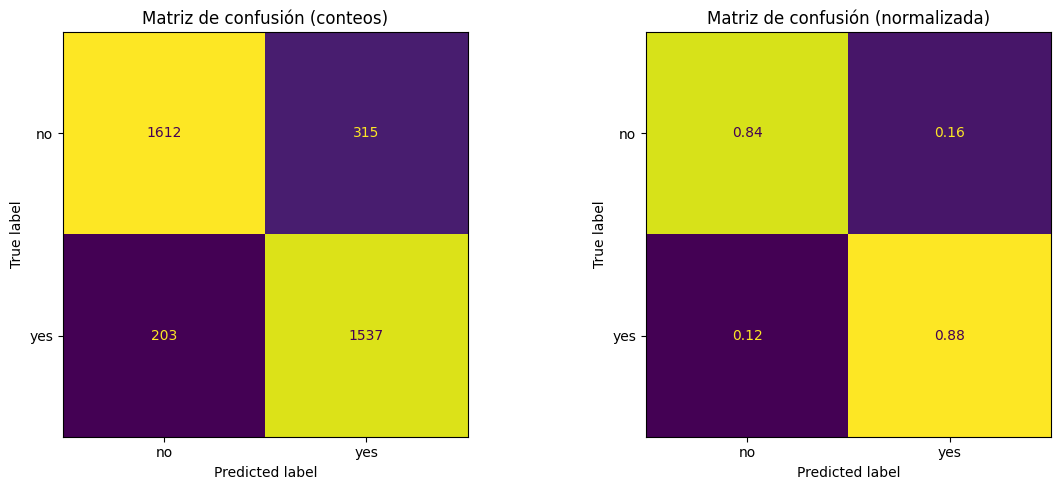

F1 inner del mejor modelo: 0.8409
F1 outer en test: 0.8558
Diferencia outer - inner: +0.0149


In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Se entrena en train la mejor alternativa seleccionada en la evaluación inner
best_model_outer = clone(best_estimator_inner)
best_model_outer.fit(X_train, y_train)

# Predicciones test
y_test_pred = best_model_outer.predict(X_test)

# ROC-AUC
if hasattr(best_model_outer, "predict_proba"):
    y_test_score = best_model_outer.predict_proba(X_test)[:, 1]
elif hasattr(best_model_outer, "decision_function"):
    y_test_score = best_model_outer.decision_function(X_test)
else:
    y_test_score = None

# Métricas outer
outer_results = {
    "F1": f1_score(y_test, y_test_pred, zero_division=0),
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
}

if y_test_score is not None:
    outer_results["ROC-AUC"] = roc_auc_score(y_test, y_test_score)

# Tabla outer
outer_results_df = pd.DataFrame({
    "Métrica": list(outer_results.keys()),
    "Valor": [round(v, 4) for v in outer_results.values()]
})
display(outer_results_df)

# Matriz confusión
cm = confusion_matrix(y_test, y_test_pred)
cm_norm = confusion_matrix(y_test, y_test_pred, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(
    ax=axes[0], colorbar=False
)
axes[0].set_title("Matriz de confusión (conteos)")

ConfusionMatrixDisplay(cm_norm, display_labels=["no", "yes"]).plot(
    ax=axes[1], colorbar=False, values_format=".2f"
)
axes[1].set_title("Matriz de confusión (normalizada)")

plt.tight_layout()
plt.show()

print(f"F1 inner del mejor modelo: {best_row['F1 medio']:.4f}")
print(f"F1 outer en test: {outer_results['F1']:.4f}")
print(f"Diferencia outer - inner: {outer_results['F1'] - best_row['F1 medio']:+.4f}")

Una vez seleccionada la **SVM con hiperparámetros por defecto** usando únicamente la evaluación inner, se ha realizado la evaluación outer sobre el conjunto de test.

El modelo obtiene un **F1-score de 0.8558**, junto con una **accuracy de 0.8587**, **precision de 0.8299**, **recall de 0.8833** y **ROC-AUC de 0.9226**. Estos resultados indican que el modelo generaliza bien sobre datos no vistos.

Además, la matriz de confusión muestra un comportamiento bastante equilibrado entre ambas clases. El modelo clasifica correctamente aproximadamente el **83.7%** de los casos de la clase `no` y el **88.3%** de los casos de la clase `yes`.

Por otra parte, el resultado outer es ligeramente superior al obtenido en la evaluación inner (0.8558 frente a 0.8409). Esta pequeña diferencia puede atribuirse a la variabilidad propia de la partición holdout, y no sugiere problemas de sobreajuste.

## 8.1 Preparación de datos para la interfaz

Antes de exportar el model final, se preparan los datos para posteriormente construir una interfaz en **Streamlit**. Esto será de utilidad para luego generar los controles de la interfaz.

Es importante no introducir variables derivadas internamente en la pipeline, como `contacted_before`, ya que esta se genera a partir de `pdays` dentro del modelo.

In [ ]:

# Mejor pipeline seleccionada tras la evaluación inner
best_pipeline = best_estimator_inner

# sin incluir variables derivadas (contacted_before)
input_num_cols = [col for col in num_cols if col != "contacted_before"]
input_cat_cols = cat_cols.copy()

X_interface = X.copy()

# diccionario
feature_metadata = {}

# Variables numéricas
for col in input_num_cols:
    s = X_interface[col].dropna()
    feature_metadata[col] = {
        "type": "numerical",
        "min": float(s.min()),
        "max": float(s.max()),
        "median": float(s.median())
    }

# Variables categóricas
for col in input_cat_cols:
    s = X_interface[col].dropna()
    feature_metadata[col] = {
        "type": "categorical",
        "options": sorted(s.astype(str).unique().tolist())
    }

# Empaquetar metadatos del modelo para la futura interfaz
model_pack = {
    "feature_metadata": feature_metadata,
    "input_num_cols": input_num_cols,
    "input_cat_cols": input_cat_cols
}

print("Datos para la interfaz generados correctamente.")
print("Variables numéricas de entrada:", input_num_cols)
print("Variables categóricas de entrada:", input_cat_cols)

Datos para la interfaz generados correctamente.
Variables numéricas de entrada: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Variables categóricas de entrada: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 8.2 Modelo final

Por último se entrena el modelo definitivo con la **mejor alternativa** utilizando **todos los datos disponibles** del dataset original. Una vez entrenado, el modelo final se guarda para utilizarlo tanto en la generación de predicciones para competición como en la futura interfaz de **Streamlit**. El modelo se guardará en dos formatos: `modelo_final.joblib` y `modelo_final.pkl`.

In [ ]:
from joblib import dump

MODEL_PATH_JOBLIB = "modelo_final.joblib"
MODEL_PATH_PKL = "modelo_final.pkl"

# Se entrena el modelo final con la alternativa ganadora según inner
final_model = clone(best_estimator_inner)
final_model.fit(X, y)

model_pack["pipeline"] = final_model
model_pack["classes_"] = final_model.named_steps["classifier"].classes_.tolist()

dump(model_pack, MODEL_PATH_JOBLIB)
dump(model_pack, MODEL_PATH_PKL)

print(f"Modelo final guardado en: {MODEL_PATH_JOBLIB}")
print(f"Copia adicional guardada en: {MODEL_PATH_PKL}")

Modelo final guardado en: modelo_final.joblib
Copia adicional guardada en: modelo_final.pkl


Una vez validado el rendimiento del modelo sobre el conjunto de test, se ha entrenado de nuevo la **SVM con hiperparámetros por defecto**, que fue la alternativa seleccionada en la evaluación inner, utilizando todos los datos disponibles del dataset original. Este modelo se ha guardado en los ficheros `modelo_final.joblib` y `modelo_final.pkl`.

# 9. Tarea de elección abierta: Random Forest

En esta sección se realiza la tarea adicional de elección abierta. Concretamente, se estudiará `RandomForestClassifier` como método de ensamblado basado en árboles para comprobar si esta familia de modelos puede aportar una mejora respecto a las alternativas evaluadas en la práctica principal.

Hemos escogido `RandomForestClassifier` debido a que en la práctica ya se ha analizado un árbol de decisión individual, por lo que resulta natural estudiar si un ensamblado de árboles permite reducir su varianza y mejorar el rendimiento.

## 9.1 Random Forest con hiperparámetros por defecto

A continuación se evaluará un `RandomForestClassifier` con sus hiperparámetros por defecto. Al tratarse de un método basado en árboles, no es necesario aplicar escalado a las variables numéricas. Esta primera evaluación servirá como referencia antes de realizar el ajuste de hiperparámetros.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

open_task_results = []

# Pipeline Random Forest
pipeline_rf_default = create_pipeline(
    model=RandomForestClassifier(random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=None
)

# Tiempo
start = time.perf_counter()

scores_rf_default = cross_validate(
    pipeline_rf_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start

print("Random Forest con hiperparámetros por defecto:")
print()
print(f"F1 medio: {scores_rf_default['test_f1'].mean():.4f} ± {scores_rf_default['test_f1'].std():.4f}")
print()
print(f"Accuracy medio: {scores_rf_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_rf_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_rf_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_rf_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_rf_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

add_result(open_task_results, "Random Forest", "por defecto", scores_rf_default["test_f1"].mean(), elapsed)

Random Forest con hiperparámetros por defecto:

F1 medio: 0.8424 ± 0.0073

Accuracy medio: 0.8448
Precision media: 0.8129
Recall medio: 0.8741
ROC-AUC medio: 0.9130
Tiempo medio de fit: 0.5520 s
Tiempo total CV: 0.7163 s


La versión por defecto de `Random Forest` obtiene un **F1 medio de 0.8424**, con una **accuracy de 0.8448**, **precision de 0.8129**, **recall de 0.8741** y **ROC-AUC de 0.9130**. Estos resultados muestran que el modelo parte de una buena posición dentro del conjunto de alternativas estudiadas.

Además, el coste computacional de esta configuración es bajo, ya que el tiempo total de validación cruzada se mantiene en torno a **menos de un segundo**. Por tanto, Random Forest por defecto ofrece un rendimiento elevado sin necesidad de ajuste adicional.

## 9.2 HPO de Random Forest

Una vez evaluado el modelo con sus hiperparámetros por defecto, se realizará un ajuste mediante `GridSearchCV`. El objetivo es comprobar si el ensamblado mejora su rendimiento y analizar si dicha mejora compensa el incremento del coste computacional.

Hiperparámetros a optimizar:
* `n_estimators`: número de árboles del bosque.
* `max_depth`: profundidad máxima de los árboles.
* `min_samples_split`: número mínimo de muestras necesario para dividir un nodo.
* `min_samples_leaf`: número mínimo de muestras en una hoja.
* `max_features`: número de variables candidatas en cada división.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Pipeline Random Forest
pipeline_rf = create_pipeline(
    model=RandomForestClassifier(random_state=SEED),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=None
)

# Grid
param_grid_rf = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__max_features": ["sqrt"]
}

grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

# Tiempo
start = time.perf_counter()

grid_rf.fit(X_train, y_train)

elapsed = time.perf_counter() - start

# Resultados
print("Random Forest con HPO")
print("Mejores hiperparámetros para Random Forest:", grid_rf.best_params_)
print(f"Mejor F1 medio: {grid_rf.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

add_result(open_task_results, "Random Forest", "HPO", grid_rf.best_score_, elapsed)

Random Forest con HPO
Mejores hiperparámetros para Random Forest: {'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Mejor F1 medio: 0.8460
Tiempo total HPO: 10.8915 segundos


Tras la optimización de hiperparámetros, la mejor configuración de `Random Forest` se obtiene con **300 árboles**, `max_depth = 20`, `min_samples_split = 10`, `min_samples_leaf = 1` y `max_features = "sqrt"`, alcanzando un **F1-score medio de 0.8460**.

En comparación con la versión por defecto, el ajuste de hiperparámetros aporta una **ligera mejora**, ya que el F1-score pasa de **0.8424** a **0.8460**. Sin embargo, esta mejora viene acompañada de un mayor coste computacional, pues el proceso completo de HPO pasa a requerir **varios segundos**, frente al tiempo muy bajo de la configuración por defecto.

Por tanto, en este caso el HPO sí permite mejorar el rendimiento, aunque la ganancia obtenida es moderada en relación con el aumento del tiempo de cómputo.

## 9.3 Análisis del efecto de los hiperparámetros en Random Forest

En esta sección se analizará el efecto de `max_depth` y `min_samples_leaf` sobre el rendimiento del modelo, fijando el resto de parámetros en los mejores valores encontrados durante el `GridSearchCV`.

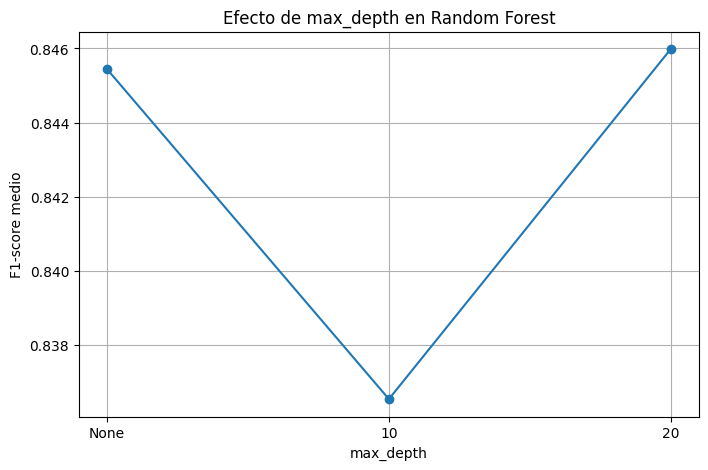

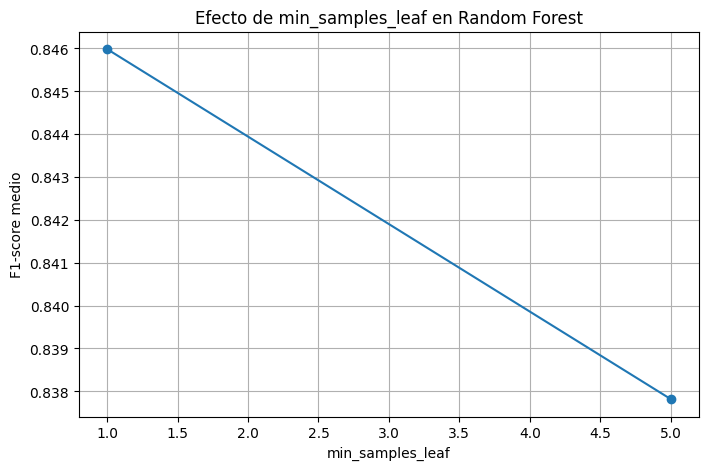

In [ ]:
results_rf = pd.DataFrame(grid_rf.cv_results_)

best_params_rf = grid_rf.best_params_

# Efecto de max_depth fijando el resto de parámetros en la mejor configuración
depth_order = ["None", "10", "20"]

plot_depth_rf = results_rf[
    (results_rf["param_classifier__n_estimators"] == best_params_rf["classifier__n_estimators"]) &
    (results_rf["param_classifier__min_samples_split"] == best_params_rf["classifier__min_samples_split"]) &
    (results_rf["param_classifier__min_samples_leaf"] == best_params_rf["classifier__min_samples_leaf"]) &
    (results_rf["param_classifier__max_features"] == best_params_rf["classifier__max_features"])
].copy()

plot_depth_rf["max_depth_label"] = plot_depth_rf["param_classifier__max_depth"].apply(
    lambda value: "None" if pd.isna(value) else str(int(value)) if isinstance(value, float) and value.is_integer() else str(value)
)
plot_depth_rf["max_depth_label"] = pd.Categorical(
    plot_depth_rf["max_depth_label"],
    categories=depth_order,
    ordered=True
)
plot_depth_rf = plot_depth_rf.sort_values("max_depth_label")

x_depth = list(range(len(plot_depth_rf)))

plt.figure(figsize=(8, 5))
plt.plot(
    x_depth,
    plot_depth_rf["mean_test_score"],
    marker="o"
)
plt.xticks(x_depth, plot_depth_rf["max_depth_label"].astype(str))
plt.title("Efecto de max_depth en Random Forest")
plt.xlabel("max_depth")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()

# Efecto de min_samples_leaf fijando el resto de parámetros en la mejor configuración
plot_leaf_rf = results_rf[
    (results_rf["param_classifier__n_estimators"] == best_params_rf["classifier__n_estimators"]) &
    (results_rf["param_classifier__max_depth"] == best_params_rf["classifier__max_depth"]) &
    (results_rf["param_classifier__min_samples_split"] == best_params_rf["classifier__min_samples_split"]) &
    (results_rf["param_classifier__max_features"] == best_params_rf["classifier__max_features"])
].sort_values("param_classifier__min_samples_leaf")

plt.figure(figsize=(8, 5))
plt.plot(
    plot_leaf_rf["param_classifier__min_samples_leaf"],
    plot_leaf_rf["mean_test_score"],
    marker="o"
)
plt.title("Efecto de min_samples_leaf en Random Forest")
plt.xlabel("min_samples_leaf")
plt.ylabel("F1-score medio")
plt.grid(True)
plt.show()

 Los gráficos anteriores permiten observar cómo influye la complejidad del bosque en el rendimiento del modelo. En este caso, la mejor configuración se alcanza con una profundidad relativamente alta (`max_depth = 20`) y con `min_samples_leaf = 1`, lo que sugiere que el ensamblado puede aprovechar árboles más profundos sin perder capacidad de generalización.

## 9.4 Conclusiones Random Forest

Por último, se resumirán los resultados obtenidos en esta tarea abierta y se compararán con el modelo final oficial de la práctica. Estos resultados se interpretan como un análisis complementario y no modifican la selección oficial del modelo final ya fijada en la sección anterior.

In [ ]:
open_task_results_df = pd.DataFrame(open_task_results)

open_task_results_df["F1 medio"] = open_task_results_df["F1 medio"].round(4)
open_task_results_df["Tiempo total (s)"] = open_task_results_df["Tiempo total (s)"].round(4)

open_task_results_df = open_task_results_df.sort_values(
    by=["F1 medio", "Tiempo total (s)"],
    ascending=[False, True]
).reset_index(drop=True)

display(open_task_results_df)

best_rf_inner = max(scores_rf_default["test_f1"].mean(), grid_rf.best_score_)
best_main_inner = best_row["F1 medio"]

print(f"Mejor F1 inner en la tarea abierta: {best_rf_inner:.4f}")
print(f"F1 inner del modelo final oficial: {best_main_inner:.4f}")
print(f"Diferencia respecto al modelo final oficial: {best_rf_inner - best_main_inner:+.4f}")

,Método,Configuración,F1 medio,Tiempo total (s)
0,Random Forest,HPO,0.8460,10.8915
1,Random Forest,por defecto,0.8424,0.7163


Mejor F1 inner en la tarea abierta: 0.8460
F1 inner del modelo final oficial: 0.8409
Diferencia respecto al modelo final oficial: +0.0051


A partir de la tabla anterior, se observa que la mejor alternativa dentro de esta tarea abierta es **Random Forest con HPO**, que alcanza un **F1 medio de 0.8460**. La versión por defecto también ofrece un resultado alto (**0.8424**), por lo que se confirma que esta familia de modelos es competitiva incluso sin ajuste.

Además, al comparar el mejor resultado de la tarea abierta con el modelo final oficial de la práctica, se obtiene una mejora de **+0.0051** en F1-score inner respecto a la **SVM con hiperparámetros por defecto** (**0.8409**). Esto indica que `Random Forest` habría sido una alternativa muy buena y que su exploración es justificable como extensión.

## Declaración del uso de la IA

En la realización de este trabajo se ha utilizado la IA como apoyo en casos puntuales. Más concretamente, se ha empleado para la generación de gráficos y, en ciertas ocasiones, como ayuda para consultar el uso de bibliotecas y funciones de herramientas como Pandas, NumPy y Scikit-learn.

